# Residual vs LSTM-style next-frame prediction: a toy world-model experiment

`main.py` trains a flow-matching model (Wan2.1 + LoRA) to predict the **next FPV frame** from the current one, an
action prompt and a 3D memory, then rolls it out autoregressively. Two changes were proposed:

| Idea | What changes |
|---|---|
| **Residual Δ** | the flow generates the *change* `(x_{t+1} - x_t) / s`, added back to `x_t` after sampling |
| **Residual bridge** | the flow still generates the full frame, but starts from `x_t + σ·noise` instead of pure noise (short path) |
| **LSTM-style state** | a small recurrent cell (ConvGRU) carries a state across steps; the denoiser reads it as extra input |

This notebook tries all six combinations of {full frame, residual Δ, residual bridge} × {stateless, recurrent state}
on dummy data with a tiny model, under the same training recipe as `main.py`: flow matching with the same shifted
timestep schedule, an unrolled sequence, self-forcing that ramps up, and one backward pass per step.

**What the dummy world tests.** Two balls move with momentum, so the next position depends on a *velocity that a
single frame does not show* (that is what a recurrent state can carry). One ball is steered by the action (like the
player). An occluder bar hides the balls as they pass behind it. Most of each frame (background, occluder) never
changes, which is what a residual parametrisation should exploit.

**What it does not test.** There is no pretrained prior: residual targets are out-of-distribution for Wan but not for a
model trained from scratch. There are no VAE latents, no 3D memory and no text prompts. The results show the trade-offs; they don't
predict Wan's numbers.

Runs on the GPU when one is available (about 30 min on an RTX 3070); `TOY_DEVICE=cpu` forces CPU, which is about 6× slower.

In [1]:
import math, os, time
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

DEVICE = os.environ.get("TOY_DEVICE", "cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(int(os.environ.get("TOY_THREADS", "8")))
torch.manual_seed(0)
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False   # reproducible reruns

H, C = 32, 3                    # frame size; 3 channels stand in for a latent frame
BATCH, BURN, UNROLL = 32, 4, 6   # sequences per step; ground-truth burn-in frames; training unroll length
ITERS, LR = 2000, 2e-3
SHIFT = 3.0                      # timestep shift, as main.py's --shift
SF_MAX, SF_STEPS = 0.5, 4        # self-forcing: max probability, Euler steps used for the self-forced frames
BRIDGE_SIGMA = 0.5               # residual bridge: noise added to x_t at the source end
GRU_CH = 16                      # recurrent state channels
N_TEST, HORIZON, EVAL_STEPS = 256, 24, 12
print(f"device {DEVICE}, {torch.get_num_threads()} threads")

device cuda, 8 threads


## 1. The dummy world

Each sequence has a static random background (blue channel), a static occluder bar at a random x, and two Gaussian
balls: **red** is steered by the action (it accelerates by `0.008·a` per step and keeps its velocity), **green** drifts
at a constant hidden velocity. Both bounce off the walls and disappear behind the bar. Values are in [-1, 1], like
`main.py`'s inputs. Actions are held for 4 steps.

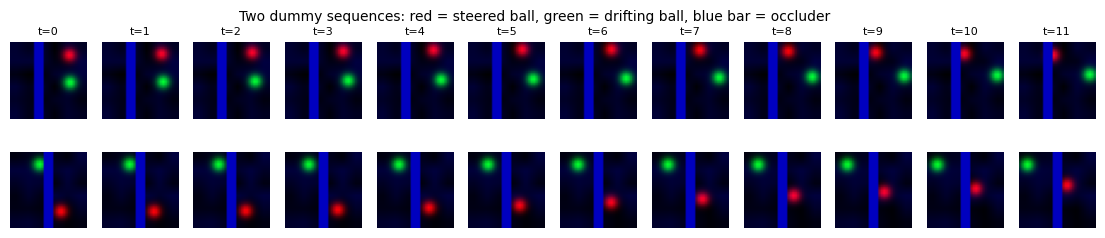

In [2]:
_ax = (torch.arange(H, device=DEVICE) + 0.5) / H
YY, XX = torch.meshgrid(_ax, _ax, indexing="ij")

def render(pos, occ, bg, r=0.06):
    # pos (B, 2 balls, 2) in [0, 1]; occ (B,) bar x; bg (B, H, W) -> frames (B, 3, H, W) in [-1, 1]
    d2 = (XX - pos[..., 0, None, None]) ** 2 + (YY - pos[..., 1, None, None]) ** 2
    blob = torch.exp(-d2 / (2 * r * r)) * 2 - 1
    bar = (XX - occ[:, None, None]).abs() < 0.07
    red, green = torch.where(bar, -1.0, blob[:, 0]), torch.where(bar, -1.0, blob[:, 1])
    return torch.stack([red, green, torch.where(bar, 0.5, bg)], 1)

def make_batch(B, T, gen=None):
    # -> frames (B, T+1, 3, H, W), actions (B, T, 2); actions[:, t] drives frame t -> t+1
    g = gen
    pos = torch.rand(B, 2, 2, generator=g, device=DEVICE) * 0.7 + 0.15
    vel = (torch.rand(B, 2, 2, generator=g, device=DEVICE) * 2 - 1) * 0.03
    occ = torch.rand(B, generator=g, device=DEVICE) * 0.5 + 0.25
    bg = -1 + 0.5 * F.interpolate(torch.rand(B, 1, 6, 6, generator=g, device=DEVICE), size=(H, H),
                                  mode="bilinear", align_corners=False)[:, 0]
    acts = torch.randint(-1, 2, (B, (T + 3) // 4, 2), generator=g, device=DEVICE).float().repeat_interleave(4, 1)[:, :T]
    frames = [render(pos, occ, bg)]
    for t in range(T):
        vel = vel.clone()
        vel[:, 0] += 0.008 * acts[:, t]                       # only the red ball is steered
        vel = vel.clamp(-0.045, 0.045)
        pos = pos + vel
        over = (pos < 0.08) | (pos > 0.92)
        vel, pos = torch.where(over, -vel, vel), pos.clamp(0.08, 0.92)
        frames.append(render(pos, occ, bg))
    return torch.stack(frames, 1), acts

show = lambda x: ((x.clamp(-1, 1) + 1) / 2).permute(1, 2, 0).cpu().numpy()
demo, _ = make_batch(2, 11, torch.Generator(device=DEVICE).manual_seed(1))
fig, ax = plt.subplots(2, 12, figsize=(14, 2.6))
for i in range(2):
    for t in range(12):
        ax[i, t].imshow(show(demo[i, t])); ax[i, t].axis("off")
        if i == 0: ax[i, t].set_title(f"t={t}", fontsize=8)
fig.suptitle("Two dummy sequences: red = steered ball, green = drifting ball, blue bar = occluder", fontsize=10)
plt.show()

## 2. The models

**Denoiser:** a tiny U-Net that stands in for the Wan DiT. It takes the same inputs as `model_pred` in `main.py`: the
noisy target, the conditioning frame `x_t`, the timestep, and the action, which plays the prompt's role and enters
through FiLM. The recurrent variants also feed it the state map.

**LSTM-style state:** a ConvGRU, the lighter sibling of a ConvLSTM with the same idea. It reads the current frame and the
action that led to it, `h_t = GRU(h_{t-1}, [x_t, a_{t-1}])`, so over a few frames it can encode velocity and
remember balls that are behind the bar.

In [3]:
class FiLMRes(nn.Module):
    def __init__(self, ch, emb):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, ch), nn.Conv2d(ch, ch, 3, padding=1)
        self.n2, self.c2 = nn.GroupNorm(8, ch), nn.Conv2d(ch, ch, 3, padding=1)
        self.film = nn.Linear(emb, 2 * ch)

    def forward(self, x, e):
        s, b = self.film(e)[:, :, None, None].chunk(2, 1)
        h = self.c1(F.silu(self.n1(x)))
        return x + self.c2(F.silu(self.n2(h) * (1 + s) + b))


class Denoiser(nn.Module):
    # (x_tau, cond frame x_t, [state]) + (tau, action) -> flow velocity; 32 -> 16 -> 8 -> 16 -> 32 U-Net
    def __init__(self, state_ch=0, w=32, emb=64):
        super().__init__()
        self.emb = nn.Sequential(nn.Linear(64 + 2, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.inp = nn.Conv2d(2 * C + state_ch, w, 3, padding=1)
        self.e1, self.d1 = FiLMRes(w, emb), nn.Conv2d(w, 2 * w, 4, 2, 1)
        self.e2, self.d2 = FiLMRes(2 * w, emb), nn.Conv2d(2 * w, 2 * w, 4, 2, 1)
        self.mid = FiLMRes(2 * w, emb)
        self.u2, self.r2 = nn.ConvTranspose2d(2 * w, 2 * w, 4, 2, 1), FiLMRes(2 * w, emb)
        self.u1, self.r1 = nn.ConvTranspose2d(2 * w, w, 4, 2, 1), FiLMRes(w, emb)
        self.out = nn.Conv2d(w, C, 3, padding=1)

    def forward(self, x, tau, cond, action, state=None):
        ang = tau[:, None] * 1000 * torch.exp(-math.log(10000) * torch.arange(32, device=x.device) / 32)
        e = self.emb(torch.cat([ang.sin(), ang.cos(), action], 1))
        h1 = self.e1(self.inp(torch.cat([x, cond] + ([state] if state is not None else []), 1)), e)
        h2 = self.e2(self.d1(h1), e)
        u2 = self.r2(self.u2(self.mid(self.d2(h2), e)) + h2, e)
        return self.out(F.silu(self.r1(self.u1(u2) + h1, e)))


class ConvGRU(nn.Module):
    # Recurrent state map: h_t = GRU(h_{t-1}, [x_t, a_{t-1}])
    def __init__(self, hid=GRU_CH, k=5):
        super().__init__()
        self.hid = hid
        self.zr = nn.Conv2d(C + 2 + hid, 2 * hid, k, padding=k // 2)
        self.n = nn.Conv2d(C + 2 + hid, hid, k, padding=k // 2)

    def init(self, B):
        return torch.zeros(B, self.hid, H, H, device=DEVICE)

    def forward(self, h, frame, prev_action):
        x = torch.cat([frame, prev_action[:, :, None, None].expand(-1, -1, H, H)], 1)
        z, r = torch.sigmoid(self.zr(torch.cat([x, h], 1))).chunk(2, 1)
        return (1 - z) * h + z * torch.tanh(self.n(torch.cat([x, r * h], 1)))


n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"denoiser {n_params(Denoiser()):,} params (+{n_params(Denoiser(GRU_CH)) - n_params(Denoiser()):,} for the state input); "
      f"ConvGRU {n_params(ConvGRU()):,}")

denoiser 500,771 params (+4,608 for the state input); ConvGRU 25,248


## 3. Three ways to set up the flow

All three use `main.py`'s rectified flow: `x_τ = (1-τ)·data + τ·source`, regress the velocity `source - data`, and
sample with Euler steps from τ = 1 to 0 on the same shifted schedule. Only the two ends of the path change:

| Parametrisation | data (τ = 0) | source (τ = 1) | after sampling | `main.py` lines it would touch |
|---|---|---|---|---|
| **full** (today) | `x_{t+1}` | `ε` | as is | none (current code) |
| **residual Δ** | `(x_{t+1} - x_t) / s` | `ε` | `x_t + s·x` | `main.py:261`, `flow.py:190` |
| **residual bridge** | `x_{t+1}` | `x_t + σ·ε` | as is | `main.py:243, 261`, `flow.py:166` |

`s` scales the change to about unit size. The global standard deviation of Δ is tiny, because almost every pixel is
static, so it is measured on the pixels that actually change; otherwise the few moving pixels would be scaled up about 40×.

In [4]:
_f, _ = make_batch(512, 1, torch.Generator(device=DEVICE).manual_seed(2))
_d = _f[:, 1] - _f[:, 0]
DELTA_SCALE = float(_d[_d.abs() > 0.05].std())
print(f"Δ std over all pixels {float(_d.std()):.3f}; over changing pixels (used as s) {DELTA_SCALE:.3f}")

def endpoints(param, curr, nxt, noise):
    # -> (data at tau = 0, source at tau = 1)
    if param == "full":
        return nxt, noise
    if param == "delta":
        return (nxt - curr) / DELTA_SCALE, noise
    return nxt, curr + BRIDGE_SIGMA * noise                     # bridge

def flow_loss(model, param, curr, nxt, action, state):
    noise = torch.randn_like(nxt)
    data, src = endpoints(param, curr, nxt, noise)
    u = torch.sigmoid(torch.randn(curr.shape[0], device=DEVICE))  # logit-normal tau, shifted as in main.py
    tau = SHIFT * u / (1 + (SHIFT - 1) * u)
    t4 = tau[:, None, None, None]
    return F.mse_loss(model((1 - t4) * data + t4 * src, tau, curr, action, state), src - data)

@torch.no_grad()
def sample(model, param, curr, action, state, steps):
    noise = torch.randn_like(curr)
    x = curr + BRIDGE_SIGMA * noise if param == "bridge" else noise
    sig = torch.linspace(1, 0, steps + 1, device=DEVICE)
    sig = SHIFT * sig / (1 + (SHIFT - 1) * sig)                  # as flow.py's predict_next_view_latents
    for i in range(steps):
        x = x - (sig[i] - sig[i + 1]) * model(x, sig[i].expand(curr.shape[0]), curr, action, state)
    return (curr + DELTA_SCALE * x if param == "delta" else x).clamp(-1, 1)

Δ std over all pixels 0.046; over changing pixels (used as s) 0.246


## 4. Training: `main.py`'s loop, plus a cheap way to train the state

The loop mirrors `main.py`. A sequence is unrolled for `UNROLL` steps, and each step runs its own `backward()` (in
`main.py` that's `ddp_model.no_sync()` plus `scaled_loss.backward()`). With a probability that ramps up to `SF_MAX`, the next
conditioning frame is the model's own prediction (self-forcing) instead of the ground truth.

**Training the recurrent state without backpropagating through time in the denoiser.** A recurrent state only learns
what to store if gradients flow back through time. Backpropagating through a 1.3B DiT across steps is out of
reach, so:

1. The GRU's small graph is **kept** across steps.
2. The denoiser receives a **detached copy** `h_in` of the state, so its graph is freed by each step's `backward()`
   as today, and that backward pass leaves `h_in.grad` (∂loss/∂state).
3. After the unroll, `torch.autograd.backward(states, grads)` pushes those gradients down the GRU chain.

The same pattern would carry over to `main.py` unchanged. The first ground-truth frames (`BURN`) only feed the state.

In [5]:
VARIANTS = {   # name: (parametrisation, recurrent state)
    "full":                  ("full",   False),
    "residual Δ":            ("delta",  False),
    "residual bridge":       ("bridge", False),
    "full + LSTM":           ("full",   True),
    "residual Δ + LSTM":     ("delta",  True),
    "residual bridge + LSTM": ("bridge", True),
}

def train(param, recurrent, iters=ITERS, seed=0):
    torch.manual_seed(seed)
    model = Denoiser(state_ch=GRU_CH if recurrent else 0).to(DEVICE)
    gru = ConvGRU().to(DEVICE) if recurrent else None
    params = list(model.parameters()) + (list(gru.parameters()) if gru else [])
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=1e-4)
    warm = max(1, iters // 20)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1.0, (i + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(i, iters) / iters)))
    losses = []
    for it in range(iters):
        frames, acts = make_batch(BATCH, BURN + UNROLL)
        p_sf = SF_MAX * min(1.0, it / (0.5 * iters))            # self-forcing ramp, as main.py
        opt.zero_grad(set_to_none=True)
        h, prev_a = (gru.init(BATCH) if gru else None), torch.zeros(BATCH, 2, device=DEVICE)
        for t in range(BURN - 1):                                # burn-in: ground truth only feeds the state
            if gru:
                h = gru(h, frames[:, t], prev_a)
            prev_a = acts[:, t]
        curr, held, total = frames[:, BURN - 1], [], 0.0
        for t in range(BURN - 1, BURN - 1 + UNROLL):
            a, h_in = acts[:, t], None
            if gru:
                h = gru(h, curr, prev_a)                         # GRU graph kept across steps (small)
                h_in = h.detach().requires_grad_()               # denoiser sees a detached copy
            loss = flow_loss(model, param, curr, frames[:, t + 1], a, h_in)
            (loss / UNROLL).backward()                           # per-step backward, as main.py
            if gru:
                held.append((h, h_in.grad))
            total += loss.item() / UNROLL
            nxt = frames[:, t + 1]
            if p_sf > 0:                                         # self-forcing: own prediction as next condition
                own = sample(model, param, curr, a, h_in.detach() if gru else None, SF_STEPS)
                nxt = torch.where((torch.rand(BATCH, device=DEVICE) < p_sf)[:, None, None, None], own, nxt)
            curr, prev_a = nxt, a
        if gru:                                                  # truncated BPTT through the GRU only
            torch.autograd.backward([s for s, _ in held], [g for _, g in held])
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        opt.step(); sched.step()
        losses.append(total)
    return model, gru, losses

In [6]:
trained = {}
for name, (param, recurrent) in VARIANTS.items():
    t0 = time.time()
    model, gru, losses = train(param, recurrent)
    trained[name] = dict(model=model.eval(), gru=gru.eval() if gru else None, param=param, recurrent=recurrent,
                         losses=losses, minutes=(time.time() - t0) / 60)
    print(f"{name:<24} {trained[name]['minutes']:5.1f} min | loss (last 50 iters) {sum(losses[-50:]) / 50:.4f}")
print("Losses are not comparable across parametrisations (each regresses a different velocity); compare rollouts below.")

full                      28.9 min | loss (last 50 iters) 0.0095


residual Δ                31.8 min | loss (last 50 iters) 0.0394


residual bridge            6.6 min | loss (last 50 iters) 0.0054


full + LSTM                6.7 min | loss (last 50 iters) 0.0041


residual Δ + LSTM          6.4 min | loss (last 50 iters) 0.0119


residual bridge + LSTM     6.4 min | loss (last 50 iters) 0.0024
Losses are not comparable across parametrisations (each regresses a different velocity); compare rollouts below.


## 5. Evaluation: long autoregressive rollouts

Each variant gets 256 unseen sequences (fixed seed). It sees `BURN` = 4 ground-truth frames: stateless variants
condition on the last one, and recurrent variants also fold all four into the state. It then predicts 24 frames,
always conditioning on its own output. Two metrics per step:

- **PSNR** of the whole frame (higher is better). The static background dominates it.
- **Ball position error** in pixels (lower is better): distance between the predicted and true centroid of each ball's
  channel, on frames where that ball is visible. A ball that has faded below 30% of its true mass counts as lost and
  scores 16 px (half the frame).

In [7]:
@torch.no_grad()
def rollout(v, frames, acts, steps=EVAL_STEPS):
    model, gru, param = v["model"], v["gru"], v["param"]
    B = frames.shape[0]
    h, prev_a = (gru.init(B) if gru else None), torch.zeros(B, 2, device=DEVICE)
    for t in range(BURN - 1):
        if gru:
            h = gru(h, frames[:, t], prev_a)
        prev_a = acts[:, t]
    curr, preds = frames[:, BURN - 1], []
    for t in range(BURN - 1, frames.shape[1] - 1):
        if gru:
            h = gru(h, curr, prev_a)
        curr = sample(model, param, curr, acts[:, t], h, steps)
        preds.append(curr); prev_a = acts[:, t]
    return torch.stack(preds, 1)                                  # (B, HORIZON, 3, H, W)

def ball_error(pred, gt):
    # per-step mean centroid distance (px) over both balls where the true ball is visible; lost ball = 16 px
    mass = lambda x: ((x[:, :, :2] + 1) / 2).clamp(min=0)          # (B, T, 2 balls, H, W)
    mp, mg = mass(pred), mass(gt)
    cen = lambda m: torch.stack([(m * XX * H).sum((-2, -1)), (m * YY * H).sum((-2, -1))], -1) / m.sum((-2, -1))[..., None].clamp(min=1e-6)
    d = (cen(mp) - cen(mg)).norm(dim=-1)                          # (B, T, 2)
    lost = mp.sum((-2, -1)) < 0.3 * mg.sum((-2, -1))
    d = torch.where(lost, torch.full_like(d, 16.0), d)
    vis = mg.sum((-2, -1)) > 8                                    # true ball (mostly) visible
    return ((d * vis).sum((0, 2)) / vis.sum((0, 2)).clamp(min=1)).cpu()

test_frames, test_acts = make_batch(N_TEST, BURN - 1 + HORIZON, torch.Generator(device=DEVICE).manual_seed(123))
gt = test_frames[:, BURN:]
results, rollouts = {}, {}
for name, v in trained.items():
    torch.manual_seed(1)
    pred = rollout(v, test_frames, test_acts)
    rollouts[name] = pred[:4]
    mse = ((pred - gt) ** 2).mean((0, 2, 3, 4)).cpu()
    results[name] = dict(psnr=(10 * torch.log10(4 / mse)), err=ball_error(pred, gt))

print(f"{'variant':<24}{'PSNR 1-4':>10}{'PSNR 5-24':>11}{'ball err 1-4':>14}{'ball err 5-24':>15}{'train min':>11}")
for name, r in results.items():
    print(f"{name:<24}{r['psnr'][:4].mean():>10.2f}{r['psnr'][4:].mean():>11.2f}"
          f"{r['err'][:4].mean():>14.2f}{r['err'][4:].mean():>15.2f}{trained[name]['minutes']:>11.1f}")

variant                   PSNR 1-4  PSNR 5-24  ball err 1-4  ball err 5-24  train min
full                         23.77      19.77          3.20          10.33       28.9
residual Δ                   23.69      19.69          3.08           9.80       31.8
residual bridge              23.63      19.70          3.37          10.72        6.6
full + LSTM                  30.00      21.16          1.82           7.10        6.7
residual Δ + LSTM            35.84      22.13          0.97           6.00        6.4
residual bridge + LSTM       31.50      21.30          1.67           7.15        6.4


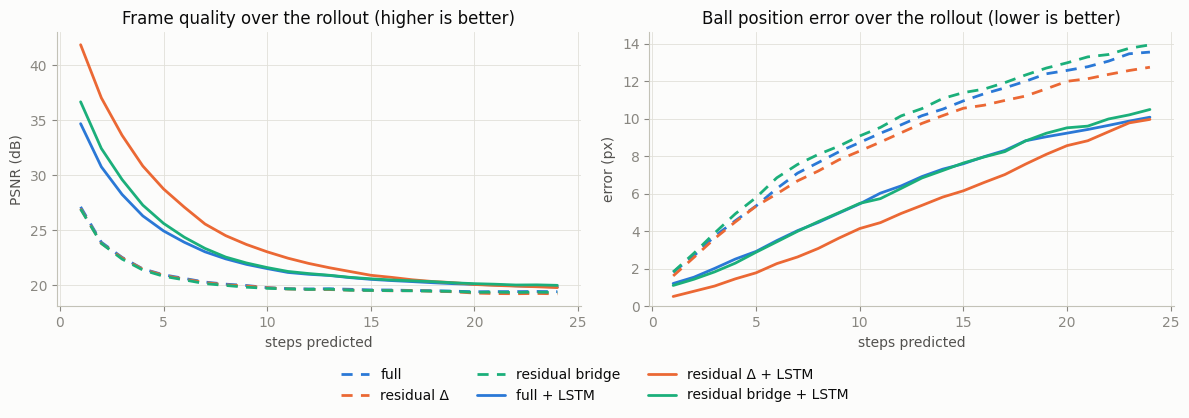

In [8]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
HUE = {"full": "#2a78d6", "delta": "#eb6834", "bridge": "#1baf7a"}   # colour = parametrisation; solid = with LSTM
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
steps = range(1, HORIZON + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, r in results.items():
    v = trained[name]
    style = dict(color=HUE[v["param"]], lw=2, ls="-" if v["recurrent"] else (0, (4, 3)), solid_capstyle="round")
    axes[0].plot(steps, r["psnr"], label=name, **style)
    axes[1].plot(steps, r["err"], **style)
axes[0].set(title="Frame quality over the rollout (higher is better)", xlabel="steps predicted", ylabel="PSNR (dB)")
axes[1].set(title="Ball position error over the rollout (lower is better)", xlabel="steps predicted", ylabel="error (px)")
axes[1].set_ylim(bottom=0)
fig.legend(loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

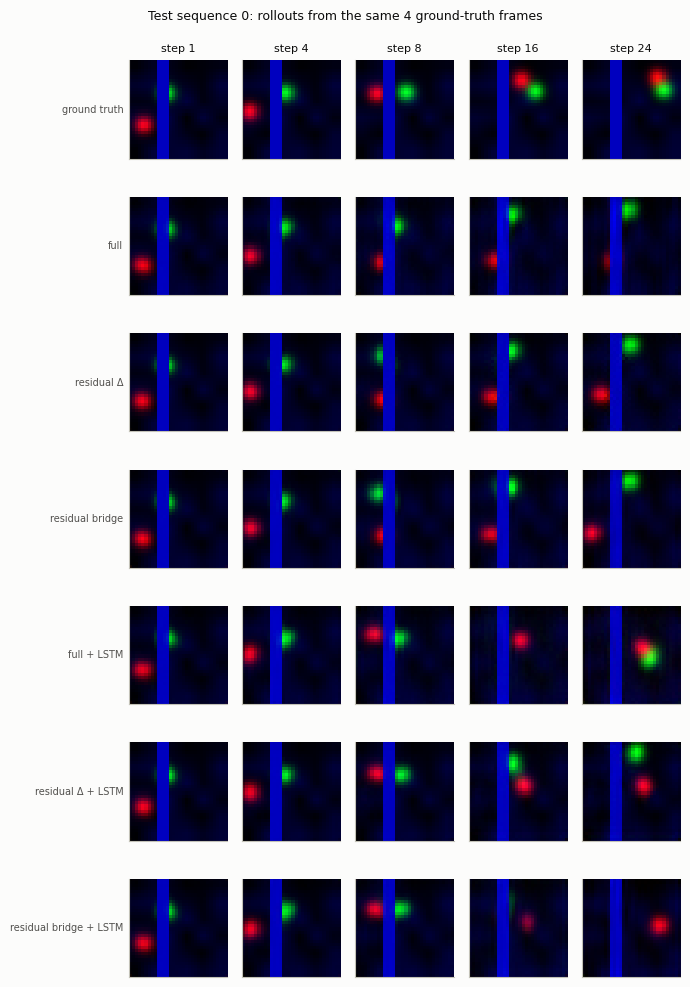

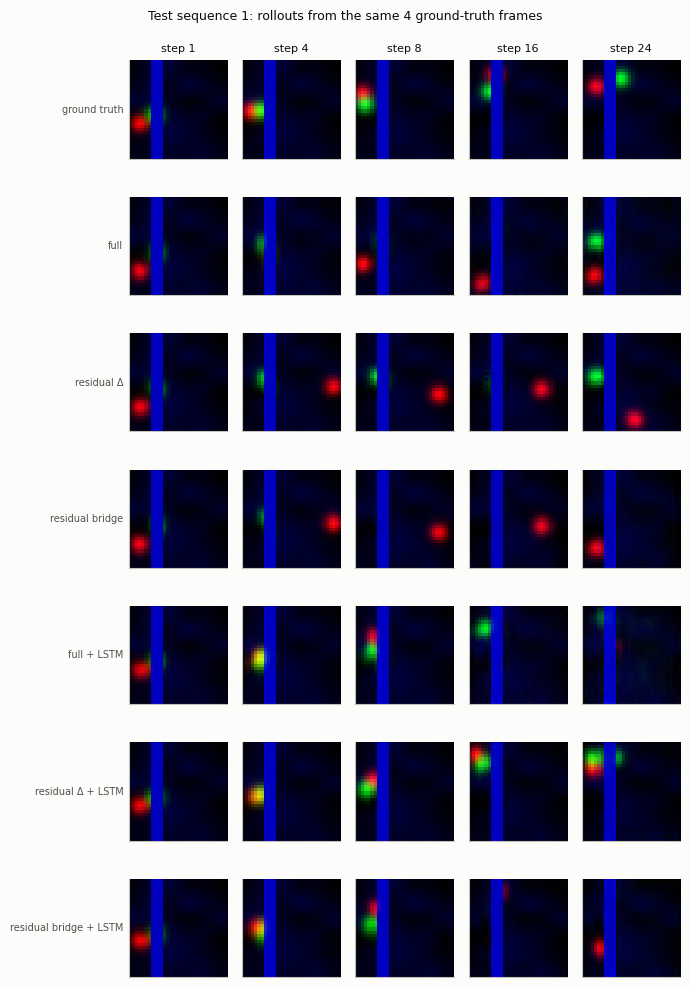

In [9]:
cols = [1, 4, 8, 16, 24]
for seq in range(2):
    fig, ax = plt.subplots(1 + len(results), len(cols), figsize=(7, 1.45 * (1 + len(results))))
    for j, s in enumerate(cols):
        ax[0, j].imshow(show(gt[seq, s - 1])); ax[0, j].set_title(f"step {s}", fontsize=8)
        for i, name in enumerate(results, 1):
            ax[i, j].imshow(show(rollouts[name][seq, s - 1]))
    for i, name in enumerate(["ground truth"] + list(results)):
        ax[i, 0].set_ylabel(name, fontsize=7, rotation=0, ha="right", va="center")
    for a in ax.flat:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.suptitle(f"Test sequence {seq}: rollouts from the same 4 ground-truth frames", fontsize=9)
    fig.tight_layout()
    plt.show()

## 6. Results

One training seed per variant, 256 test sequences. An earlier run, identical except for the plot layout, gave the same
numbers to within 0.35 dB and 0.4 px. The `train min` column is wall time on a shared GPU, not a cost comparison: the first
two variants ran while another job was using the GPU.

| Variant | PSNR, steps 1–4 | PSNR, steps 5–24 | Ball error (px), steps 1–4 | Ball error (px), steps 5–24 |
|---|---|---|---|---|
| full | 23.77 | 19.77 | 3.20 | 10.33 |
| residual Δ | 23.69 | 19.69 | 3.08 | 9.80 |
| residual bridge | 23.63 | 19.70 | 3.37 | 10.72 |
| full + LSTM | 30.00 | 21.16 | 1.82 | 7.10 |
| **residual Δ + LSTM** | **35.84** | **22.13** | **0.97** | **6.00** |
| residual bridge + LSTM | 31.50 | 21.30 | 1.67 | 7.15 |

1. **The recurrent state matters most.** It adds 6–12 dB at short range and roughly halves the ball error. From a single
   frame the model can't see velocity, so the stateless rollouts slow the balls down or jump them across the occluder
   (see the rollout figures): when the velocity is unknown, the safest guess is to stay put.
2. **On its own, a residual makes no measurable difference here.** All three stateless variants are within 0.15 dB of
   each other. Their error comes from the missing velocity, not from redrawing the static background.
3. **Residual Δ pays off once the state supplies the velocity.** Δ + LSTM is best on every metric: +5.8 dB over
   full + LSTM at steps 1–4, a ball error of 0.97 vs 1.82 px, and still ahead at steps 5–24 (22.13 vs 21.16 dB, 6.0 vs 7.1 px).
   With the motion known, drawing only the change is easier than redrawing the whole frame.
4. **The bridge behaves like the full-frame baseline.** With the state it is a little better at short range (31.5 vs 30.0 dB)
   and the same after that.
5. **Everything still drifts.** By step 24 ball errors reach 13–14 px without the state and about 10 px with it, and PSNR
   falls to about 20 dB, a level set mostly by the static background.

**Caveats.** There is only one training seed, so don't read much into gaps under 0.5 dB. The toy has no pretrained prior:
in Wan, a Δ target is out of distribution for the prior, which could shrink its lead, while the bridge keeps full-frame
outputs. The state is trained with truncated backpropagation through time over the 6-step unroll.

## 7. Two heads on one trunk, and how to combine them

Same denoiser and ConvGRU state as before, but the output layer has extra heads, all computed in **one forward pass**:

| Channels | Head | Trained to predict |
|---|---|---|
| `0:C` | Δ head | the velocity of the scaled change `(x_{t+1} - x_t) / s`, as the residual Δ model in section 3 |
| `C:2C` | full head | the clean next frame `x_{t+1}` directly |
| `2C:3C` | gate (optional) | a per-feature weight between the two heads, trained on the blended estimate |

**Why the full head predicts the frame rather than a velocity.** The change is scaled by `s`, like `DELTA_SCALE` in
`main.py`, so the full-frame flow and the Δ flow no longer share a noise path, and their velocities can't be blended
directly. What both heads *can* give, at any noise level, is an estimate of the clean next frame:
`x_t + s·(y - τ·v_Δ)` from the Δ head, and the full head's output. Every combination below blends those two estimates,
then converts the result back to a velocity for the Euler step.

| Combination | What it does |
|---|---|
| Δ head only | ignores the full head (the residual Δ sampler from section 3) |
| full head only | uses the full head's estimate at every step |
| average | averages the two estimates everywhere |
| **agreement blend (σ)** | per feature: averages where the two estimates agree within about σ, trusts the Δ head where they don't; the "keep high-agreement features" idea |
| + ULA corrector | the agreement blend plus one unadjusted Langevin step at each noise level (the score-only sampler from Du et al. 2023) |
| **best-of-K** | P/Q importance resampling: draw K samples from the Δ head (Q), weight each by how well the full head reconstructs it from a noised copy (a stand-in for P_full), keep the best |
| **learned gate** | the third head chooses the per-feature weight; trained on the blended estimate |

All models in this section are trained here with the same recipe and evaluated on the same 256 test sequences as
section 5. The single Δ head with state is retrained as the baseline so every comparison is within one run. One
model has no state, which is closest to the current `main.py`.

In [6]:
class HeadsDenoiser(Denoiser):
    # Same trunk as Denoiser; output channels [0:C] change velocity, [C:2C] clean next frame, [2C:3C] gate logits
    def __init__(self, state_ch=0, heads=2):
        super().__init__(state_ch)
        self.out = nn.Conv2d(self.out.in_channels, heads * C, 3, padding=1)
        if heads == 3:                                    # gate starts at sigmoid(-4) ~ 0.02: trust the delta head
            with torch.no_grad():
                self.out.weight[2 * C:].zero_()
                self.out.bias[2 * C:].fill_(-4.0)


def estimates(out, y, tau, curr):
    # Each head's estimate of the clean next frame, plus the gate's weight on the full head (if there is a gate)
    t4 = tau.view(-1, 1, 1, 1) if tau.dim() == 1 else tau
    from_delta = curr + DELTA_SCALE * (y - t4 * out[:, :C])      # change = y - tau * velocity, rescaled, + current
    from_full = out[:, C:2 * C]
    gate = torch.sigmoid(out[:, 2 * C:]) if out.shape[1] > 2 * C else None
    return from_delta, from_full, gate


def heads_loss(model, curr, nxt, action, state):
    noise = torch.randn_like(nxt)
    change = (nxt - curr) / DELTA_SCALE
    u = torch.sigmoid(torch.randn(curr.shape[0], device=DEVICE))
    tau = SHIFT * u / (1 + (SHIFT - 1) * u)
    t4 = tau[:, None, None, None]
    y = (1 - t4) * change + t4 * noise
    out = model(y, tau, curr, action, state)
    loss = F.mse_loss(out[:, :C], noise - change) + F.mse_loss(out[:, C:2 * C], nxt)
    if out.shape[1] > 2 * C:                              # gate: train the blended estimate itself
        from_delta, from_full, gate = estimates(out, y, tau, curr)
        loss = loss + F.mse_loss(gate * from_full + (1 - gate) * from_delta, nxt)
    return loss


@torch.no_grad()
def sample_heads(model, curr, action, state, steps, mode="delta", sigma=0.1, ula=0.0):
    # mode: delta | full | average | agree | gate. Euler steps on the scaled change; returns the next frame.
    def velocity(y, tau):
        out = model(y, tau.expand(curr.shape[0]), curr, action, state)
        from_delta, from_full, gate = estimates(out, y, tau, curr)
        if mode == "delta":
            est = from_delta
        elif mode == "full":
            est = from_full
        elif mode == "average":
            est = 0.5 * (from_delta + from_full)
        elif mode == "agree":                              # average where the heads agree (within ~sigma)
            agree = torch.exp(-(from_delta - from_full) ** 2 / (2 * sigma ** 2))
            est = agree * 0.5 * (from_delta + from_full) + (1 - agree) * from_delta
        else:                                              # learned gate
            est = gate * from_full + (1 - gate) * from_delta
        return (y - (est - curr) / DELTA_SCALE) / tau      # back to a velocity of the change

    y = torch.randn_like(curr)
    sig = torch.linspace(1, 0, steps + 1, device=DEVICE)
    sig = SHIFT * sig / (1 + (SHIFT - 1) * sig)
    for i in range(steps):
        y = y - (sig[i] - sig[i + 1]) * velocity(y, sig[i])
        if ula > 0 and sig[i + 1] > 0:                     # one unadjusted Langevin step at the new noise level
            t = sig[i + 1]
            eps_hat = y + (1 - t) * velocity(y, t)         # change = y - t*v and eps = change + v
            step = ula * t ** 2
            y = y - step * eps_hat / t + (2 * step) ** 0.5 * torch.randn_like(y)
    return (curr + DELTA_SCALE * y).clamp(-1, 1)


@torch.no_grad()
def best_of_k(model, curr, action, state, steps, K=4, taus=(0.3, 0.6)):
    # P/Q importance resampling: K samples from the delta head (Q), each weighted by how well the full head
    # reconstructs it from a noised copy (a stand-in for P_full); keep the highest-weight sample per sequence
    cands = torch.stack([sample_heads(model, curr, action, state, steps, "delta") for _ in range(K)])
    log_w = torch.zeros(K, curr.shape[0], device=DEVICE)
    for k in range(K):
        for tau in taus:
            y = (1 - tau) * (cands[k] - curr) / DELTA_SCALE + tau * torch.randn_like(curr)
            out = model(y, torch.full((curr.shape[0],), tau, device=DEVICE), curr, action, state)
            log_w[k] -= ((out[:, C:2 * C] - cands[k]) ** 2).mean((1, 2, 3))
    return cands[log_w.argmax(0), torch.arange(curr.shape[0], device=DEVICE)]


def train_heads(heads, recurrent, iters=ITERS, seed=0):
    # Section 4's loop with heads_loss; self-forcing uses the delta head (or the learned gate, if there is one)
    torch.manual_seed(seed)
    model = HeadsDenoiser(state_ch=GRU_CH if recurrent else 0, heads=heads).to(DEVICE)
    gru = ConvGRU().to(DEVICE) if recurrent else None
    sf_mode = "gate" if heads == 3 else "delta"
    params = list(model.parameters()) + (list(gru.parameters()) if gru else [])
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=1e-4)
    warm = max(1, iters // 20)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1.0, (i + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(i, iters) / iters)))
    for it in range(iters):
        frames, acts = make_batch(BATCH, BURN + UNROLL)
        p_sf = SF_MAX * min(1.0, it / (0.5 * iters))
        opt.zero_grad(set_to_none=True)
        h, prev_a = (gru.init(BATCH) if gru else None), torch.zeros(BATCH, 2, device=DEVICE)
        for t in range(BURN - 1):
            if gru:
                h = gru(h, frames[:, t], prev_a)
            prev_a = acts[:, t]
        curr, held = frames[:, BURN - 1], []
        for t in range(BURN - 1, BURN - 1 + UNROLL):
            a, h_in = acts[:, t], None
            if gru:
                h = gru(h, curr, prev_a)
                h_in = h.detach().requires_grad_()
            (heads_loss(model, curr, frames[:, t + 1], a, h_in) / UNROLL).backward()
            if gru:
                held.append((h, h_in.grad))
            nxt = frames[:, t + 1]
            if p_sf > 0:
                own = sample_heads(model, curr, a, h_in.detach() if gru else None, SF_STEPS, sf_mode)
                nxt = torch.where((torch.rand(BATCH, device=DEVICE) < p_sf)[:, None, None, None], own, nxt)
            curr, prev_a = nxt, a
        if gru:
            torch.autograd.backward([s for s, _ in held], [g for _, g in held])
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        opt.step(); sched.step()
    return model, gru

In [7]:
HEAD_MODELS = {   # name: (number of heads (1 = section 3's single delta head), recurrent state)
    "single Δ + LSTM":         (1, True),
    "two heads + LSTM":        (2, True),
    "two heads + gate + LSTM": (3, True),
    "two heads (no state)":    (2, False),
}
head_models = {}
for name, (heads, recurrent) in HEAD_MODELS.items():
    t0 = time.time()
    if heads == 1:
        model, gru, _ = train("delta", True)
    else:
        model, gru = train_heads(heads, recurrent)
    head_models[name] = (model.eval(), gru.eval() if gru else None)
    print(f"{name:<26} trained in {(time.time() - t0) / 60:4.1f} min")

single Δ + LSTM            trained in  4.3 min


two heads + LSTM           trained in  4.2 min


two heads + gate + LSTM    trained in  4.3 min


two heads (no state)       trained in  3.7 min


In [8]:
def ball_error(pred, gt):
    # as in section 5: per-step centroid distance (px) over both balls where the true ball is visible; lost = 16 px
    mass = lambda x: ((x[:, :, :2] + 1) / 2).clamp(min=0)
    mp, mg = mass(pred), mass(gt)
    cen = lambda m: torch.stack([(m * XX * H).sum((-2, -1)), (m * YY * H).sum((-2, -1))], -1) / m.sum((-2, -1))[..., None].clamp(min=1e-6)
    d = (cen(mp) - cen(mg)).norm(dim=-1)
    d = torch.where(mp.sum((-2, -1)) < 0.3 * mg.sum((-2, -1)), torch.full_like(d, 16.0), d)
    vis = mg.sum((-2, -1)) > 8
    return ((d * vis).sum((0, 2)) / vis.sum((0, 2)).clamp(min=1)).cpu()

test_frames, test_acts = make_batch(N_TEST, BURN - 1 + HORIZON, torch.Generator(device=DEVICE).manual_seed(123))
gt = test_frames[:, BURN:]

@torch.no_grad()
def evaluate(sampler, gru):
    # section 5's protocol: 4 ground-truth frames, then HORIZON steps on the model's own output
    torch.manual_seed(1)
    B = test_frames.shape[0]
    h, prev_a = (gru.init(B) if gru else None), torch.zeros(B, 2, device=DEVICE)
    for t in range(BURN - 1):
        if gru:
            h = gru(h, test_frames[:, t], prev_a)
        prev_a = test_acts[:, t]
    curr, preds = test_frames[:, BURN - 1], []
    for t in range(BURN - 1, test_frames.shape[1] - 1):
        if gru:
            h = gru(h, curr, prev_a)
        curr = sampler(curr, test_acts[:, t], h)
        preds.append(curr); prev_a = test_acts[:, t]
    pred = torch.stack(preds, 1)
    mse = ((pred - gt) ** 2).mean((0, 2, 3, 4)).cpu()
    return dict(psnr=10 * torch.log10(4 / mse), err=ball_error(pred, gt))

S = EVAL_STEPS
heads_with = lambda m, **kw: (lambda c, a, h: sample_heads(m, c, a, h, S, **kw))
EVALS = [   # (label, model, sampler factory)
    ("single Δ head (baseline)",        "single Δ + LSTM",         lambda m: (lambda c, a, h: sample(m, "delta", c, a, h, S))),
    ("two heads: Δ head only",          "two heads + LSTM",        lambda m: heads_with(m, mode="delta")),
    ("two heads: full head only",       "two heads + LSTM",        lambda m: heads_with(m, mode="full")),
    ("two heads: average",              "two heads + LSTM",        lambda m: heads_with(m, mode="average")),
] + [
    (f"two heads: agree σ={s}",         "two heads + LSTM",        (lambda s: lambda m: heads_with(m, mode="agree", sigma=s))(s))
    for s in (0.02, 0.05, 0.1, 0.2)
] + [
    (f"two heads: agree σ=0.1 + ULA {u}", "two heads + LSTM",      (lambda u: lambda m: heads_with(m, mode="agree", sigma=0.1, ula=u))(u))
    for u in (0.02, 0.1)
] + [
    ("two heads: best-of-4",            "two heads + LSTM",        lambda m: (lambda c, a, h: best_of_k(m, c, a, h, S))),
    ("gate model: learned gate",        "two heads + gate + LSTM", lambda m: heads_with(m, mode="gate")),
    ("gate model: Δ head only",         "two heads + gate + LSTM", lambda m: heads_with(m, mode="delta")),
    ("no state: Δ head only",           "two heads (no state)",    lambda m: heads_with(m, mode="delta")),
    ("no state: full head only",        "two heads (no state)",    lambda m: heads_with(m, mode="full")),
    ("no state: agree σ=0.1",           "two heads (no state)",    lambda m: heads_with(m, mode="agree", sigma=0.1)),
]
print(f"{'':<34}{'PSNR':>8}{'PSNR':>9}{'err px':>9}{'err px':>9}\n{'':<34}{'1-4':>8}{'5-24':>9}{'1-4':>9}{'5-24':>9}")
head_results = {}
for label, model_name, make in EVALS:
    model, gru = head_models[model_name]
    t0 = time.time()
    head_results[label] = evaluate(make(model), gru)
    r = head_results[label]
    print(f"{label:<34}{r['psnr'][:4].mean():>8.2f}{r['psnr'][4:].mean():>9.2f}{r['err'][:4].mean():>9.2f}{r['err'][4:].mean():>9.2f}"
          f"   ({time.time() - t0:.0f} s)")

                                      PSNR     PSNR   err px   err px
                                       1-4     5-24      1-4     5-24


single Δ head (baseline)             35.84    22.13     0.97     6.00   (4 s)


two heads: Δ head only               35.52    22.09     0.89     5.48   (4 s)


two heads: full head only            30.56    20.13     2.32     6.56   (4 s)


two heads: average                   33.50    21.40     1.58     5.87   (4 s)


two heads: agree σ=0.02              35.44    22.08     0.96     5.44   (4 s)


... (7 outputs left out)

gate model: Δ head only              35.31    22.33     0.89     5.10   (4 s)


no state: Δ head only                23.59    19.70     3.03     9.90   (4 s)


no state: full head only             22.92    18.08     3.65     9.37   (4 s)


no state: agree σ=0.1                23.50    19.44     3.16     9.64   (4 s)


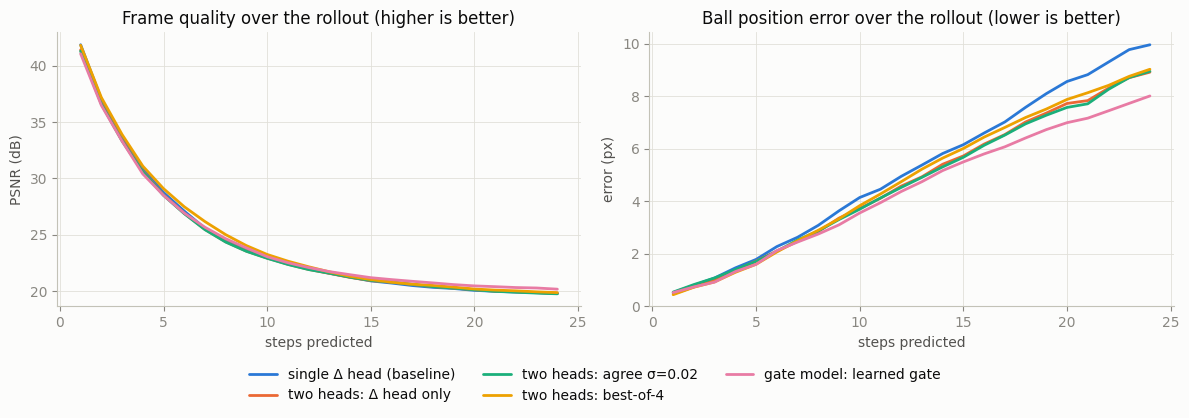

In [9]:
# Chart: the two-heads results (key combinations only; the full table is printed above)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
steps = range(1, HORIZON + 1)
agree_rows = [k for k in head_results if k.startswith("two heads: agree σ=") and "ULA" not in k]
best_agree = max(agree_rows, key=lambda k: head_results[k]["psnr"].mean().item())
KEY = ["single Δ head (baseline)", "two heads: Δ head only", best_agree, "two heads: best-of-4", "gate model: learned gate"]
KEY_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed categorical order (validated)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for label, color in zip(KEY, KEY_COLORS):
    r = head_results[label]
    axes[0].plot(steps, r["psnr"], color=color, lw=2, label=label, solid_capstyle="round")
    axes[1].plot(steps, r["err"], color=color, lw=2, solid_capstyle="round")
axes[0].set(title="Frame quality over the rollout (higher is better)", xlabel="steps predicted", ylabel="PSNR (dB)")
axes[1].set(title="Ball position error over the rollout (lower is better)", xlabel="steps predicted", ylabel="error (px)")
axes[1].set_ylim(bottom=0)
fig.legend(loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

## 8. Results: two heads

One training seed per model, evaluated on the same 256 test sequences as section 5. The baseline reproduces
section 5's residual Δ + LSTM row exactly. All rows except the last use the ConvGRU state.

| Combination | PSNR, steps 1–4 | PSNR, steps 5–24 | Ball error (px), steps 1–4 | Ball error (px), steps 5–24 | Time |
|---|---|---|---|---|---|
| single Δ head (baseline) | 35.84 | 22.13 | 0.97 | 6.00 | 1× |
| two heads: Δ head only | 35.52 | 22.09 | 0.89 | 5.48 | 1× |
| two heads: full head only | 30.56 | 20.13 | 2.32 | 6.56 | 1× |
| two heads: average | 33.50 | 21.40 | 1.58 | 5.87 | 1× |
| two heads: agreement blend, σ = 0.02 / 0.1 / 0.2 | 35.44 / 34.33 / 33.84 | 22.08 / 21.66 / 21.48 | 0.96 / 1.49 / 1.56 | 5.44 / 5.72 / 5.84 | 1× |
| two heads: agreement σ = 0.1 + ULA corrector | 34.19 | 21.60 | 1.50 | 6.00 | 2× |
| **two heads: best-of-4 (P/Q importance resampling)** | **35.99** | 22.33 | **0.85** | 5.61 | about 5× |
| **gate model: learned gate** | 35.31 | **22.34** | 0.88 | **5.08** | 1× |
| gate model: Δ head only | 35.31 | 22.33 | 0.89 | 5.10 | 1× |
| no state: Δ head only / full head only / agreement σ = 0.1 | 23.59 / 22.92 / 23.50 | 19.70 / 18.08 / 19.44 | 3.03 / 3.65 / 3.16 | 9.90 / 9.37 / 9.64 | 1× |

1. **Blending the heads at inference doesn't help.** The full head on its own is much worse than the Δ head
   (30.6 vs 35.5 dB), so any weight given to it costs accuracy. Averaging loses 2 dB. The agreement blend gets worse as σ
   grows, and at the smallest σ it simply reproduces the Δ head. The ULA corrector adds nothing at twice the cost.
   Keeping "high-agreement features" can't beat the better head when the other head is uniformly worse and both share
   one trunk. (In the chart, "Δ head only" sits under "agree σ=0.02" because the two are nearly identical.)
2. **The second head helps as a training signal instead.** With the same Δ-head sampler, the long-horizon ball error
   falls from 6.00 px (single head) to 5.48 (two heads) to 5.10 (two heads + gate), about 15% better, with PSNR within
   ±0.3 dB. The learned gate's blend scores the same as its own Δ head (5.08 vs 5.10), so the gate learned to trust the
   Δ head almost everywhere. Its benefit therefore came during training, from the extra loss on the blended (≈ Δ-head)
   estimate of the clean next frame. *Untested hypothesis:* a single Δ head with that frame-space loss added would get
   the same gain without any extra head.
3. **Best-of-4 is the only inference-time combination that helps.** Compared with its own Δ head it gains +0.5 dB at
   steps 1–4 and +0.2 dB later, and the short-range ball error drops slightly (0.85 vs 0.89), but the long-range error
   rises slightly (5.61 vs 5.48). It costs 4 samples plus 8 scoring passes per frame.
4. **Without a state, nothing here helps.** The two-head Δ head (23.59 dB) matches section 5's stateless Δ (23.69), and
   blending is again worse. The missing velocity is still the dominant error.

**Caveats.** One seed. The 0.4–0.9 px differences between the Δ-head variants are plausible but need a second seed to
confirm. The toy also clamps every frame to [-1, 1], which hides drift that unclamped Wan latents would show.

## 9. Porting to `main.py`

- **Residual bridge:** in training, replace the noise source with `source = curr_latents + σ·noise`, so
  `noisy = (1-τ)·target + τ·source` (`main.py:243`) and `target_velocity = source - target_latents` (`main.py:261`). In
  the sampler, start from `x_tau = latents_t.float() + σ·randn` (`flow.py:166`). Your
  `predict_next_view_latents_sketch` already starts from a non-noise source this way.
- **Residual Δ:** `target_latents → (target_latents - curr_latents) / s` (`main.py:261`) and return
  `latents_t + s·x_tau` (`flow.py:190`). `s` should be measured on the latents that change, not on all of them.
- **LSTM-style state:** a small ConvGRU over the FPV latent (`(B, C, 1, h, w)`), with its output fed in as one more
  conditioning frame next to `memory_latents` (`main.py:258`, `flow.py:182`). Train it with the detach-and-collect-grads
  pattern from section 4 around the per-step `scaled_loss.backward()` (`main.py:282`), then call
  `torch.autograd.backward(states, grads)` before `optimizer.step()`. The DiT's graph is still freed every step.
- **Order to try in `main.py`:** add the state first, since it is the large effect here. Then compare Δ + state and
  bridge + state side by side: Δ won in this toy, but Wan's pretrained prior knows full frames, not frame
  differences, which favours the bridge in the real model.

- **Two heads.** `main.py` now scales Δ (`DELTA_SCALE = 0.2`) and takes it relative to the noised context, so a second
  head must predict the clean next latent directly, as in section 7. A full-frame *velocity* head only lines up with the
  Δ flow when the scale is 1. Going by section 8: if you add one, sample with the Δ head alone and treat the second head
  as an extra training loss; skip inference-time blending. Try best-of-K only when sampling budget allows. Before adding
  a head at all, test the cheaper version: an extra loss on the Δ head's own clean-frame estimate,
  `x_t + s·(y - τ·v_Δ)` compared with the next latent.